# sales-analytics



In [1]:
import pandas as pd

df = pd.read_csv("data/Sample - Superstore.csv", encoding="latin1")
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [2]:
print(df[["Order Date", "Ship Date"]].dtypes)
print(df["Order Date"].min(), "to", df["Order Date"].max())

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object
2014-01-03 00:00:00 to 2017-12-30 00:00:00
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5,009


In [3]:
print("Dataset Shape:", df.shape)
print(df.columns.tolist())
df.info()
print(df.isnull().sum())
print("Duplicate Rows:", df.duplicated().sum())
df[["Sales", "Quantity", "Discount", "Profit"]].describe()
    

Dataset Shape: (9994, 21)
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  S

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [4]:
category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum")
).round(2)
category_analysis = category_analysis.sort_values(by="Total_Sales", ascending=False)
category_analysis["Profit_Margin_%"] = (category_analysis["Total_Profit"] / category_analysis["Total_Sales"] * 100).round(1)

category_analysis

,Total_Sales,Total_Profit,Units_Sold,Profit_Margin_%
Category,,,,
Technology,836154.03,145454.95,6939,17.4
Furniture,741999.80,18451.27,8028,2.5
Office Supplies,719047.03,122490.80,22906,17.0


### Category Performance

- **Technologyhas** the highest sales (~$836K) and the highest profit (~$145K), with a profit **17.4%**.
- **Office** Supplies sells the most units (22,906) and earns a similar margin of about **17.0%**
- **Furniture** has sales close to the other two categories (~$742K), but only ~$18K in profit, a margin of just **2.5%**.
- Furniture is the weak spot: high revenue but very little profit

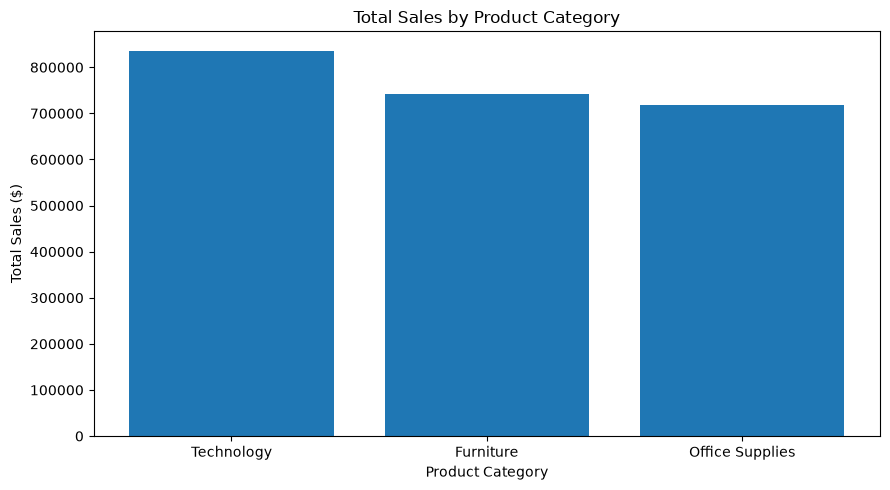

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))
plt.bar(category_analysis.index, category_analysis["Total_Sales"])
plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales ($)")
plt.tight_layout()
plt.show()

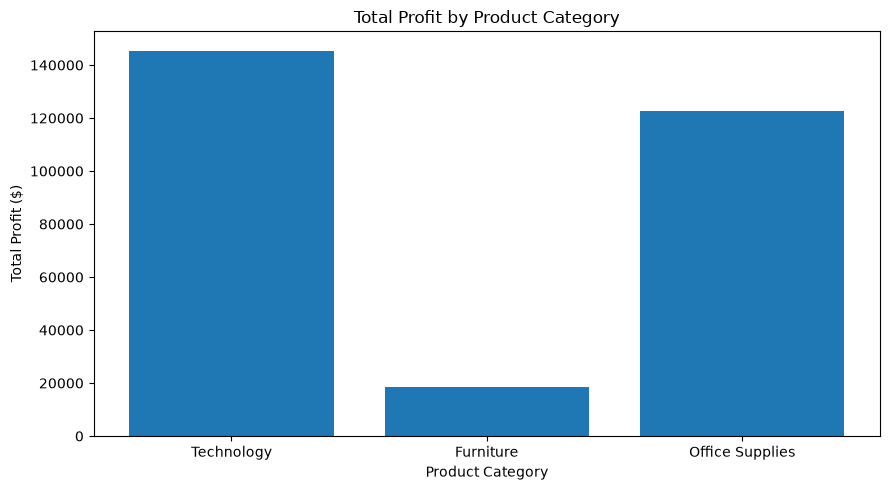

In [6]:

plt.figure(figsize=(9, 5))
plt.bar(category_analysis.index, category_analysis["Total_Profit"])
plt.title("Total Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit ($)")
plt.tight_layout()
plt.show()

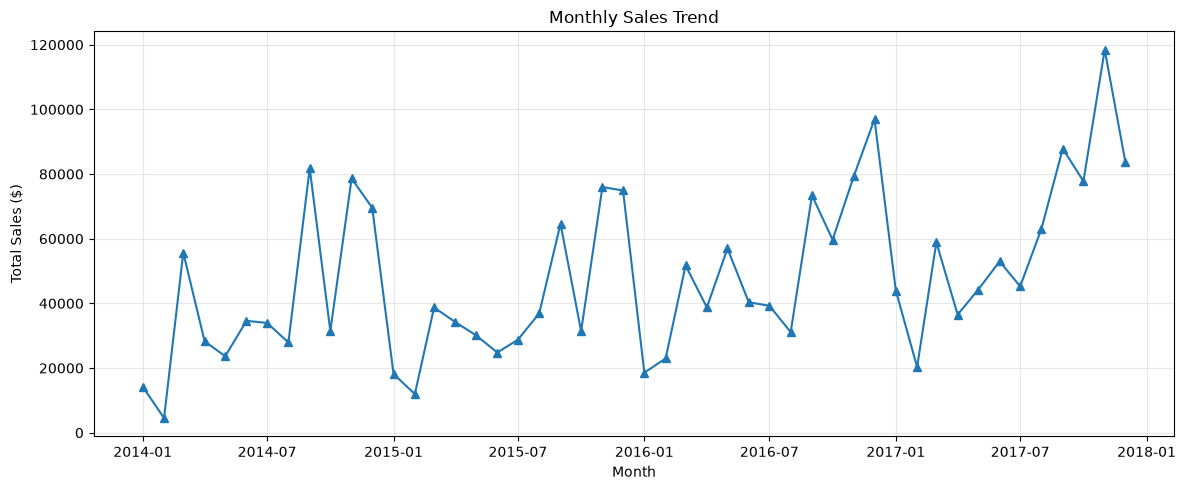

In [7]:
monthly_sales = df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum()
monthly_sales.index = monthly_sales.index.to_timestamp()

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="^")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
best_month = monthly_sales.idxmax()
worst_month = monthly_sales.idxmin()

print(f"Highest: {best_month:%B %Y} -> ${monthly_sales.max():,.2f}")
print(f"Lowest: {worst_month:%B %Y} -> ${monthly_sales.min():,.2f}")
monthly_sales.sort_values(ascending=False).head(3)


Highest: November 2017 -> $118,447.82
Lowest: February 2014 -> $4,519.89


Order Date
2017-11-01    118447.825
2016-12-01     96999.043
2017-09-01     87866.652
Name: Sales, dtype: float64

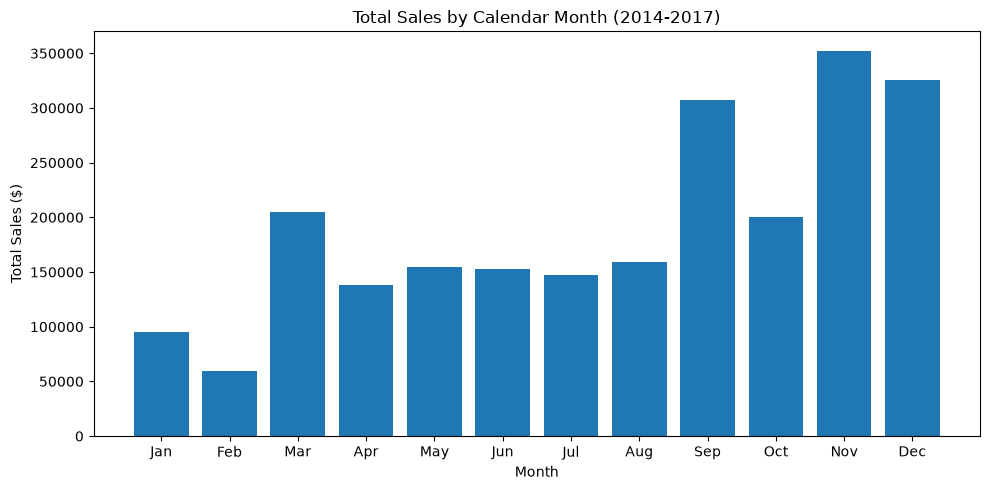

In [9]:
seasonal_sales = df.groupby(df["Order Date"].dt.month)["Sales"].sum()
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(10, 5))
plt.bar(month_names, seasonal_sales.values)
plt.title("Total Sales by Calendar Month (2014-2017)")
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.tight_layout()
plt.show()

In [10]:
seasonal_share = (seasonal_sales / seasonal_sales.sum() * 100).round(1)
seasonal_share.index = month_names

print(seasonal_share.sort_values(ascending=False))
top_three = seasonal_share[["Sep", "Nov", "Dec"]].sum()

print(f"Sep + Nov + Dec = {top_three:.1f}% of total sales")

Nov    15.3
Dec    14.2
Sep    13.4
Mar     8.9
Oct     8.7
Aug     6.9
May     6.7
Jun     6.6
Jul     6.4
Apr     6.0
Jan     4.1
Feb     2.6
Name: Sales, dtype: float64
Sep + Nov + Dec = 42.9% of total sales


### Insight 1: Strong Seasonality in Sales

- Sales are concentrated in the last months of the year: **September, November, and December** together generate **42.9%** of total sales, compared to the 25% we would expect if sales were evenly distributed across 3 months.
- The single highest month was **November 2017** (~$118K in sales).
- **Recommendation:** Plan inventory, staffing, and marketing campaigns ahead of Q3-Q4 to capture peak demand.

In [11]:
subcat = df.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).round(2)
subcat["Profit_Margin_%"] = (subcat["Total_Profit"] / subcat["Total_Sales"] * 100).round(1)
subcat = subcat.sort_values("Total_Profit")
subcat

,Total_Sales,Total_Profit,Profit_Margin_%
Sub-Category,,,
Tables,206965.53,-17725.48,-8.6
Bookcases,114880.00,-3472.56,-3.0
Supplies,46673.54,-1189.10,-2.5
Fasteners,3024.28,949.52,31.4
Machines,189238.63,3384.76,1.8
Labels,12486.31,5546.25,44.4
Art,27118.79,6527.79,24.1
Envelopes,16476.40,6964.18,42.3
Furnishings,91705.16,13059.14,14.2


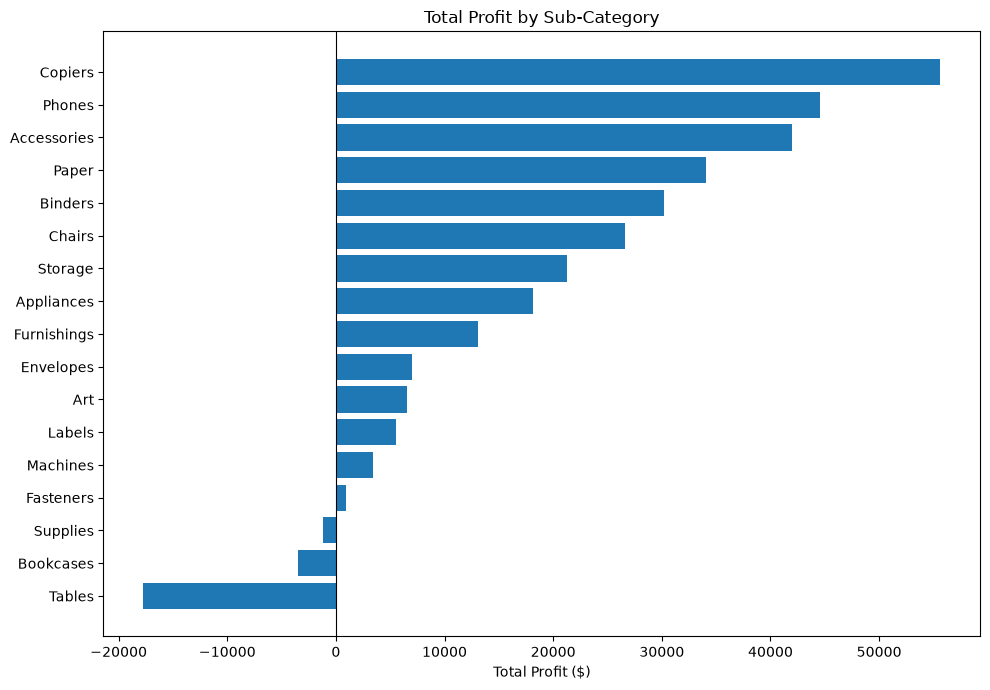

In [12]:
plt.figure(figsize=(10, 7))
plt.barh(subcat.index, subcat["Total_Profit"])
plt.title("Total Profit by Sub-Category")
plt.xlabel("Total Profit ($)")

plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**Observation:** Three sub-categories are loss-making: **Tables** (-$17,725, -8.6% margin), **Bookcases** (-$3,473, -3.0%), and **Supplies** (-$1,189, -2.5%). Tables lose money despite being among the higher-selling sub-categories (~$207K in sales).

In [13]:
discount_by_subcat = (
    df.groupby("Sub-Category")["Discount"]
    .mean()
    .sort_values(ascending=False)
    .round(3)
)

print(discount_by_subcat)
print("Overall Average Discount:", round(df["Discount"].mean(), 3))

Sub-Category
Binders        0.372
Machines       0.306
Tables         0.261
Bookcases      0.211
Chairs         0.170
Appliances     0.167
Copiers        0.162
Phones         0.155
Furnishings    0.138
Fasteners      0.082
Envelopes      0.080
Accessories    0.078
Supplies       0.077
Paper          0.075
Art            0.075
Storage        0.075
Labels         0.069
Name: Discount, dtype: float64
Overall Average Discount: 0.156


In [14]:
df["Discount_Band"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0, 0.2, 0.4, 1.0],
    labels=["No discount", "1-20%", "21-40%", "Over 40%"]
)

band_analysis = df.groupby("Discount_Band", observed=True).agg(
    Order_Lines=("Row ID", "count"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).round(2)

band_analysis["Profit_Margin_%"] = (band_analysis["Total_Profit"] / band_analysis["Total_Sales"] * 100).round(1)
band_analysis

,Order_Lines,Total_Sales,Total_Profit,Profit_Margin_%
Discount_Band,,,,
No discount,4798,1087908.47,320987.60,29.5
1-20%,3803,846522.24,100785.47,11.9
21-40%,460,234137.90,-35817.47,-15.3
Over 40%,933,128632.25,-99558.59,-77.4


### Insight 2: Heavy Discounts Destroy Profitability

- Profit margin falls steadily as discounts increase: **29.5%** with no discount, **11.9%** at 1-20%, **-15.3%** at 21-40%, and **-77.4%** above 40%.
- Order lines with discounts above 20% make up only ~14% of all lines and ~16% of sales, yet generate combined losses of about **$135K**, roughly 47% of the company's total profit ($286K).
- Tables (avg. discount 26.1%) and Bookcases (21.1%) are loss-making and sit well above the overall average discount of 15.6%.
- **Recommendation:** Cap discounts at 20% (especially on Furniture) and review the discount policy for Tables and Bookcases.

**Note:** Supplies is also loss-making but its average discount is low (7.7%), so discounts do not explain its loss. This would need a deeper look in a follow-up analysis.

## <span style="color:#1f77b4">Summary</span>

1. <span style="color:#16a085">**Seasonality:** 42.9% of total sales come from September, November, and December. November 2017 was the highest month (~$118K).</span>

2. <span style="color:#e67e22">**Profitability problem:** Furniture earns only a 2.5% margin compared to ~17% for Technology and Office Supplies. Tables (-$17,725), Bookcases (-$3,473), and Supplies (-$1,189) are loss-making.</span>

3. <span style="color:#8e44ad">**Discounts:** profit margin falls from 29.5% with no discount to -15.3% at 21-40% and -77.4% above 40%. Margins turn negative once discounts exceed 20%.</span>

<span style="color:#c0392b">**Recommendations:**</span> plan inventory and marketing ahead of the Q3-Q4 peak, cap discounts at 20%, and review the discount policy for Tables and Bookcases.